## Polynomial Regression

### Polynomial regression is a form of regression analysis where the relationship between the independent variable x and the dependent variable y is modeled as an nth degree polynomial.  It is a special case of multiple linear regression that allows for the modeling of nonlinear relationships by fitting a curve to data rather than a straight line. 

#### y=b0​+b1​x+b2​x2+b3​x3

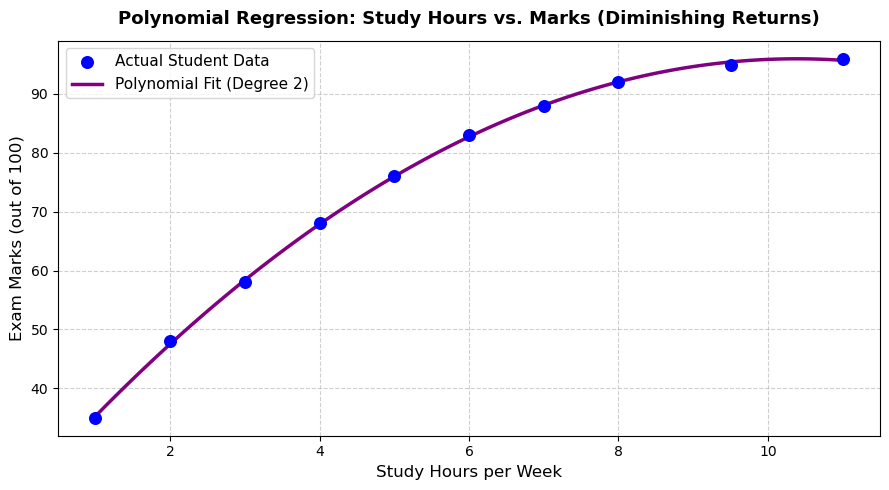

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Non-Linear Sample Data (Diminishing returns at higher study hours)
# X: Study hours per week
X = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.5, 11.0]).reshape(-1, 1)
# y: Exam marks (notice how marks curve off and plateau around 95-98)
y = np.array([35, 48, 58, 68, 76, 83, 88, 92, 95, 96])

# 2. Transform features to include polynomial terms (e.g., degree 2 -> adds X^2)
degree = 2
poly_features = PolynomialFeatures(degree=degree, include_bias=False)
X_poly = poly_features.fit_transform(X)

# 3. Train a standard Linear Regression model on the polynomial features
model = LinearRegression()
model.fit(X_poly, y)

# 4. Generate smooth points for plotting the curve
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
X_range_poly = poly_features.transform(X_range)
y_pred = model.predict(X_range_poly)

# 5. Visualization
plt.figure(figsize=(9, 5))

# Plot actual data points
plt.scatter(X, y, color='blue', label='Actual Student Data', s=70, zorder=3)

# Plot the fitted polynomial curve
plt.plot(X_range, y_pred, color='purple', linewidth=2.5, label=f'Polynomial Fit (Degree {degree})', zorder=2)

# Graph styling
plt.title('Polynomial Regression: Study Hours vs. Marks (Diminishing Returns)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Study Hours per Week', fontsize=12)
plt.ylabel('Exam Marks (out of 100)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6, zorder=1)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()